# EDA và Tiền xử lý dữ liệu IMU (`acc_*`, `rot_*`)

Notebook này thực hiện phân tích dữ liệu khám phá (EDA) chuyên sâu cho nhóm cảm biến chuyển động IMU gồm:
- **Gia tốc kế 3 trục (`acc_x`, `acc_y`, `acc_z`)**
- **Quaternion định hướng (`rot_w`, `rot_x`, `rot_y`, `rot_z`)**

Mục tiêu:
1. Khảo sát phân bố, dữ liệu thiếu và tính chất vật lý của tín hiệu IMU.
2. Kiểm chứng sự khác biệt giữa người thuận tay trái và tay phải (`handedness`).
3. Thử nghiệm và kiểm chứng các đặc trưng hỗ trợ tốt cho **mô hình cây (Tree-based)** đồng thời giữ nguyên cấu trúc chuỗi thời gian.
4. Kết nối và kiểm chứng trực tiếp hàm `preprocess_imu` trong `src/preprocess_imu.py`.

In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Allow importing preprocessing module from ../src
SRC_DIR = Path("../src").resolve()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from preprocess_imu import ACC_COLS, FEATURE_COLS, IMU_COLS, ROT_COLS, preprocess_imu

DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)

In [11]:
META_COLS = [
    "sequence_id",
    "sequence_counter",
    "subject",
    "sequence_type",
    "orientation",
    "behavior",
    "phase",
    "gesture",
]

train = pd.read_csv(DATA_DIR / "train.csv", usecols=META_COLS + IMU_COLS)
demo = pd.read_csv(DATA_DIR / "train_demographics.csv")

print("Train IMU subset shape:", train.shape)
print("Demographics shape:", demo.shape)
train[IMU_COLS].describe().T

Train IMU subset shape: (574945, 15)
Demographics shape: (81, 8)


,count,mean,std,min,25%,50%,75%,max
acc_x,574945.0,1.639980,5.781259,-34.585938,-2.964844,2.972656,6.343750,46.328125
acc_y,574945.0,1.790704,5.003945,-24.402344,-2.121094,0.695312,6.816406,27.183594
acc_z,574945.0,-0.459811,6.096490,-42.855469,-5.417969,-1.562500,5.164062,30.078125
rot_w,571253.0,0.360375,0.225739,0.000000,0.180237,0.340332,0.503479,0.999390
rot_x,571253.0,-0.119916,0.465520,-0.999146,-0.456299,-0.186890,0.204590,0.999817
rot_y,571253.0,-0.059953,0.543028,-0.999695,-0.511536,-0.112610,0.440063,0.999451
rot_z,571253.0,-0.188298,0.504137,-0.998169,-0.627686,-0.263916,0.251099,0.999878


## 1. Phân tích dữ liệu thiếu và chuẩn hóa Quaternion (`rot_*`)

Theo `01_eda_overview.ipynb`, `acc_*` không có giá trị thiếu, còn `rot_*` bị mất trọn vẹn ở 50 chuỗi (3 người). Phần dưới đây kiểm tra chi tiết mẫu thiếu, chuẩn độ dài (norm) của quaternion và hiện tượng đảo dấu $q \equiv -q$ giữa hai bước liên tiếp.

In [12]:
# Check missing counts per column
print("Missing count per IMU column:")
print(train[IMU_COLS].isna().sum())

# Inspect sequences where rot_* is missing
rot_nan_row = train[ROT_COLS].isna().any(axis=1)
rot_miss_seq = (
    train.assign(rot_nan=rot_nan_row)
    .groupby("sequence_id")
    .agg(
        subject=("subject", "first"),
        gesture=("gesture", "first"),
        orientation=("orientation", "first"),
        nan_frac=("rot_nan", "mean"),
    )
)
missing_seqs = rot_miss_seq[rot_miss_seq["nan_frac"] > 0]
print(f"\nTotal sequences with any rot_* NaN: {len(missing_seqs)}")
print("Missing fraction value counts:", missing_seqs["nan_frac"].value_counts().to_dict())
print("\nMissing sequences by subject:")
print(missing_seqs["subject"].value_counts())

# Check unit norm of non-missing quaternions
valid_q = train.loc[~rot_nan_row, ROT_COLS].to_numpy(dtype=np.float64)
q_norm = np.linalg.norm(valid_q, axis=1)
print("\nQuaternion norm summary on valid rows:")
print(pd.Series(q_norm).describe())

# Check sign flips (q_t . q_{t-1} < 0) within consecutive time steps of valid sequences
valid_df = train.loc[~rot_nan_row, ["sequence_id", "sequence_counter"] + ROT_COLS].sort_values(
    ["sequence_id", "sequence_counter"]
)
q_curr = valid_df[ROT_COLS].to_numpy(dtype=np.float64)
q_prev = valid_df.groupby("sequence_id", sort=False)[ROT_COLS].shift(1).to_numpy(dtype=np.float64)
same_seq = ~np.isnan(q_prev).any(axis=1)
raw_dot = np.sum(q_curr[same_seq] * q_prev[same_seq], axis=1)
print(
    f"\nConsecutive steps with negative quaternion dot product (q -> -q): "
    f"{(raw_dot < 0).sum()} ({(raw_dot < 0).mean():.2%})"
)

Missing count per IMU column:
acc_x       0
acc_y       0
acc_z       0
rot_w    3692
rot_x    3692
rot_y    3692
rot_z    3692
dtype: int64

Total sequences with any rot_* NaN: 50
Missing fraction value counts: {1.0: 50}

Missing sequences by subject:
subject
SUBJ_058967    24
SUBJ_055211    18
SUBJ_053217     8
Name: count, dtype: int64

Quaternion norm summary on valid rows:
count    571253.000000
mean          1.000000
std           0.000018
min           0.999943
25%           0.999987
50%           1.000000
75%           1.000013
max           1.000056
dtype: float64

Consecutive steps with negative quaternion dot product (q -> -q): 13644 (2.42%)


## 2. Ảnh hưởng của tay thuận (`handedness`) và kiểm chứng lật trục (Mirroring)

Trong `train_demographics.csv`, `handedness = 1` là thuận tay phải (71 người) và `handedness = 0` là thuận tay trái (10 người, ~12,3%). Vì đồng hồ đeo đối xứng trên cổ tay trái vs phải, trục `acc_x` bị đảo dấu (được quan sát trên `SUBJ_002923` ở notebook 01).

Dưới đây kiểm tra phân bố của tất cả các trục `acc_*` và `rot_*` theo `handedness`, sau đó kiểm chứng hiệu quả trước và sau khi phản chiếu qua mặt phẳng YZ ($x \mapsto -x$, tức `acc_x -> -acc_x`, `rot_y -> -rot_y`, `rot_z -> -rot_z`).

Sequence-level mean by handedness (0=Left, 1=Right):
            acc_x         acc_y         acc_z         rot_w        rot_x  \
             mean median   mean median   mean median   mean median  mean   
handedness                                                                 
0          -1.623 -1.907  2.371  2.968 -1.154 -1.204  0.328  0.315  0.24   
1           1.770  2.219  1.970  1.968 -0.916 -0.916  0.353  0.342 -0.16   

                   rot_y         rot_z         
           median   mean median   mean median  
handedness                                     
0           0.373 -0.199 -0.207 -0.184 -0.202  
1          -0.175 -0.030  0.014 -0.153 -0.115  


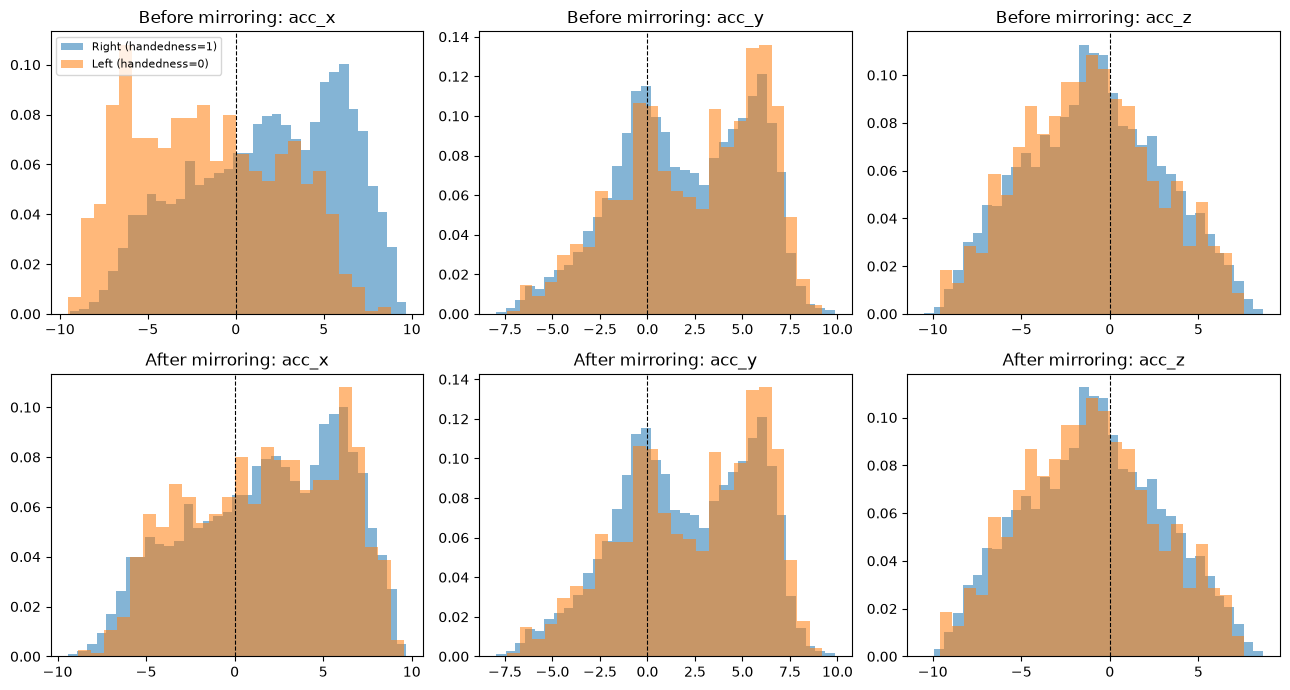

In [13]:
train_hand = train.merge(demo[["subject", "handedness"]], on="subject", how="left")

# Compare sequence-level mean per axis across handedness groups
seq_means = train_hand.groupby(["sequence_id", "handedness"], as_index=False)[IMU_COLS].mean()
print("Sequence-level mean by handedness (0=Left, 1=Right):")
print(seq_means.groupby("handedness")[IMU_COLS].agg(["mean", "median"]).round(3))

# Plot acc_* distribution before and after mirroring
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col_idx, col in enumerate(ACC_COLS):
    right_vals = seq_means.loc[seq_means["handedness"] == 1, col]
    left_vals = seq_means.loc[seq_means["handedness"] == 0, col]

    ax_top = axes[0, col_idx]
    ax_top.hist(right_vals, bins=35, density=True, alpha=0.55, label="Right (handedness=1)")
    ax_top.hist(left_vals, bins=25, density=True, alpha=0.55, label="Left (handedness=0)")
    ax_top.set_title(f"Before mirroring: {col}")
    ax_top.axvline(0, color="k", linestyle="--", linewidth=0.8)
    if col_idx == 0:
        ax_top.legend(fontsize=8)

    ax_bot = axes[1, col_idx]
    left_mirrored = -left_vals if col == "acc_x" else left_vals
    ax_bot.hist(right_vals, bins=35, density=True, alpha=0.55, label="Right (unchanged)")
    ax_bot.hist(left_mirrored, bins=25, density=True, alpha=0.55, label="Left (mirrored)")
    ax_bot.set_title(f"After mirroring: {col}")
    ax_bot.axvline(0, color="k", linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.savefig(FIG_DIR / "imu_handedness_mirroring.png", dpi=150)
plt.show()

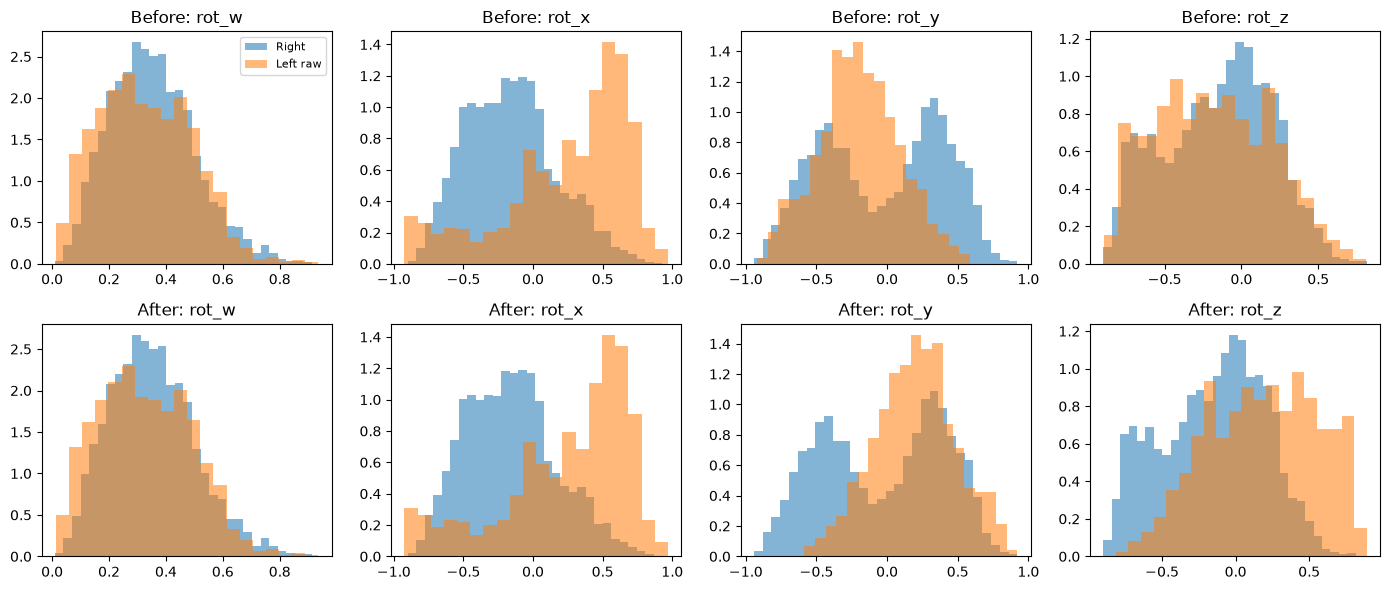

In [14]:
# Compare quaternion component distributions between right and left handedness (valid rot only)
valid_seq_q = (
    train_hand.dropna(subset=ROT_COLS)
    .groupby(["sequence_id", "handedness"], as_index=False)[ROT_COLS]
    .mean()
)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for col_idx, col in enumerate(ROT_COLS):
    right_q = valid_seq_q.loc[valid_seq_q["handedness"] == 1, col]
    left_q = valid_seq_q.loc[valid_seq_q["handedness"] == 0, col]

    axes[0, col_idx].hist(right_q, bins=30, density=True, alpha=0.55, label="Right")
    axes[0, col_idx].hist(left_q, bins=20, density=True, alpha=0.55, label="Left raw")
    axes[0, col_idx].set_title(f"Before: {col}")

    left_q_mirrored = -left_q if col in ("rot_y", "rot_z") else left_q
    axes[1, col_idx].hist(right_q, bins=30, density=True, alpha=0.55, label="Right")
    axes[1, col_idx].hist(left_q_mirrored, bins=20, density=True, alpha=0.55, label="Left mirrored")
    axes[1, col_idx].set_title(f"After: {col}")

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "imu_rot_mirroring.png", dpi=150)
plt.show()

## 3. Khám phá tín hiệu thô và động cơ tạo đặc trưng cho mô hình cây (Tree-based)

Nhóm định hướng sử dụng **mô hình cây (Tree-based)** (bên cạnh các mô hình chuỗi nếu có). Mô hình cây phân nhánh độc lập theo từng cột (`feature > threshold`), nên gặp hai hạn chế với dữ liệu IMU thô:
1. **Không tự học được hình học 3D:** Khó kết hợp 3 trục `(acc_x, acc_y, acc_z)` thành độ lớn vận động (`acc_mag`) hoặc góc nghiêng cổ tay (`acc_pitch`, `acc_roll`), cũng như khó đọc trực tiếp 4 thành phần quaternion (`rot_w/x/y/z`) so với góc Euler (`rot_roll`, `rot_pitch`, `rot_yaw`).
2. **Không có bộ nhớ thời gian:** Một dòng ở thời điểm $t$ không biết tay đang rung lắc hay đứng yên nếu không có đặc trưng biến thiên cục bộ (`acc_jerk`, `acc_mag_roll_std_5`, `acc_dyn_mag`, `rot_ang_vel`).

Các bước dưới đây chạy thử `preprocess_imu`, kiểm tra các quy ước bắt buộc và trực quan hóa mức độ phân tách của các đặc trưng mới.

In [15]:
# Run preprocess_imu on full train data
imu_proc = preprocess_imu(train, demo)
print("Processed IMU shape:", imu_proc.shape)
print("Columns:", imu_proc.columns.tolist())

# 1. Verify mandatory constraints (row count, key order, zero NaNs)
assert len(imu_proc) == len(train), "Row count mismatch!"
assert (imu_proc["sequence_id"].values == train["sequence_id"].values).all(), "sequence_id mismatch!"
assert (imu_proc["sequence_counter"].values == train["sequence_counter"].values).all(), "sequence_counter mismatch!"
assert imu_proc.isna().sum().sum() == 0, "Output contains NaN!"

# 2. Verify test-set compatibility (drop train-only label/context columns)
test_like_cols = ["sequence_id", "sequence_counter", "subject"] + IMU_COLS
imu_test_like = preprocess_imu(train[test_like_cols], demo)
pd.testing.assert_frame_equal(imu_proc, imu_test_like)
print("Test-set compatibility check PASSED!")

# 3. Verify strict per-sequence independence (no cross-sequence leakage)
sample_sid = train["sequence_id"].iloc[0]
single_seq_df = train[train["sequence_id"] == sample_sid].copy()
imu_single = preprocess_imu(single_seq_df, demo)
imu_from_full = imu_proc[imu_proc["sequence_id"] == sample_sid].reset_index(drop=True)
pd.testing.assert_frame_equal(imu_single, imu_from_full)
print("Per-sequence independence check PASSED!")

Processed IMU shape: (574945, 21)
Columns: ['sequence_id', 'sequence_counter', 'acc_x', 'acc_y', 'acc_z', 'rot_w', 'rot_x', 'rot_y', 'rot_z', 'rot_missing', 'acc_mag', 'acc_pitch', 'acc_roll', 'acc_jerk', 'acc_mag_roll_mean_5', 'acc_mag_roll_std_5', 'acc_dyn_mag', 'rot_roll', 'rot_pitch', 'rot_yaw', 'rot_ang_vel']
Test-set compatibility check PASSED!
Per-sequence independence check PASSED!


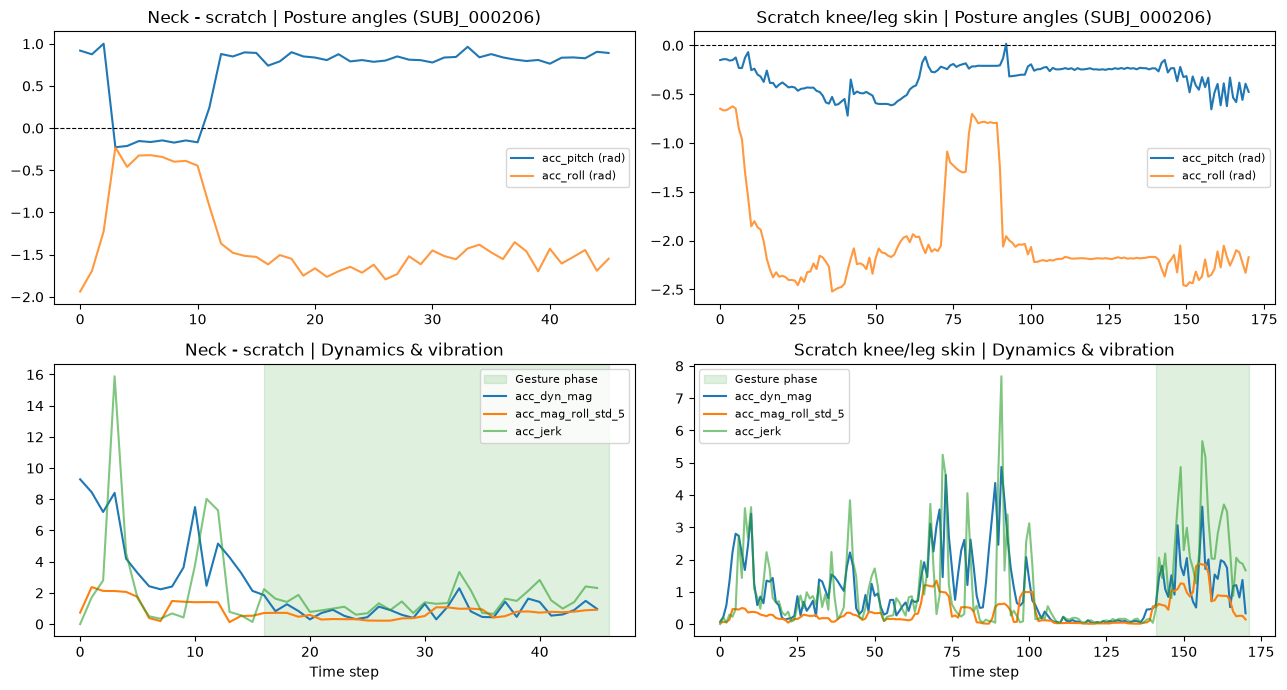

In [16]:
# Visualize how engineered features highlight gesture phase and wrist posture
pair = ["Neck - scratch", "Scratch knee/leg skin"]
meta_seq = train[["sequence_id", "subject", "gesture", "orientation"]].drop_duplicates("sequence_id")
pick = meta_seq[
    meta_seq["gesture"].isin(pair)
    & (meta_seq["orientation"] == "Seated Lean Non Dom - FACE DOWN")
]
subj_counts = pick.groupby("subject")["gesture"].nunique()
subj_id = subj_counts[subj_counts == 2].index[0]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for col_idx, g in enumerate(pair):
    sid = pick.loc[(pick["subject"] == subj_id) & (pick["gesture"] == g), "sequence_id"].iloc[0]
    raw_s = train[train["sequence_id"] == sid].sort_values("sequence_counter")
    proc_s = imu_proc[imu_proc["sequence_id"] == sid].sort_values("sequence_counter")

    # Top: wrist tilt angles separate Neck vs Knee posture
    ax_top = axes[0, col_idx]
    ax_top.plot(proc_s["sequence_counter"], proc_s["acc_pitch"], label="acc_pitch (rad)")
    ax_top.plot(proc_s["sequence_counter"], proc_s["acc_roll"], label="acc_roll (rad)", alpha=0.8)
    ax_top.axhline(0, color="k", linestyle="--", linewidth=0.8)
    ax_top.set_title(f"{g} | Posture angles ({subj_id})")
    ax_top.legend(fontsize=8)

    # Bottom: dynamic acceleration & local std highlight repetitive gesture phase
    ax_bot = axes[1, col_idx]
    is_gesture = raw_s["phase"] == "Gesture"
    if is_gesture.any():
        g_start = raw_s.loc[is_gesture, "sequence_counter"].min()
        g_end = raw_s.loc[is_gesture, "sequence_counter"].max() + 1
        ax_bot.axvspan(g_start, g_end, color="tab:green", alpha=0.15, label="Gesture phase")
    ax_bot.plot(proc_s["sequence_counter"], proc_s["acc_dyn_mag"], label="acc_dyn_mag")
    ax_bot.plot(proc_s["sequence_counter"], proc_s["acc_mag_roll_std_5"], label="acc_mag_roll_std_5")
    ax_bot.plot(proc_s["sequence_counter"], proc_s["acc_jerk"], label="acc_jerk", alpha=0.6)
    ax_bot.set_title(f"{g} | Dynamics & vibration")
    ax_bot.set_xlabel("Time step")
    ax_bot.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "imu_engineered_signals.png", dpi=150)
plt.show()

Sequence-level feature median by sequence_type (Target=BFRB vs Non-Target):
sequence_type            Non-Target  Target
acc_mag_mean                 10.034   9.940
acc_pitch_mean                0.235   0.229
acc_dyn_mag_mean              2.171   1.550
acc_mag_roll_std_5_mean       0.659   0.474
acc_jerk_mean                 2.059   1.469
rot_ang_vel_mean              0.137   0.099


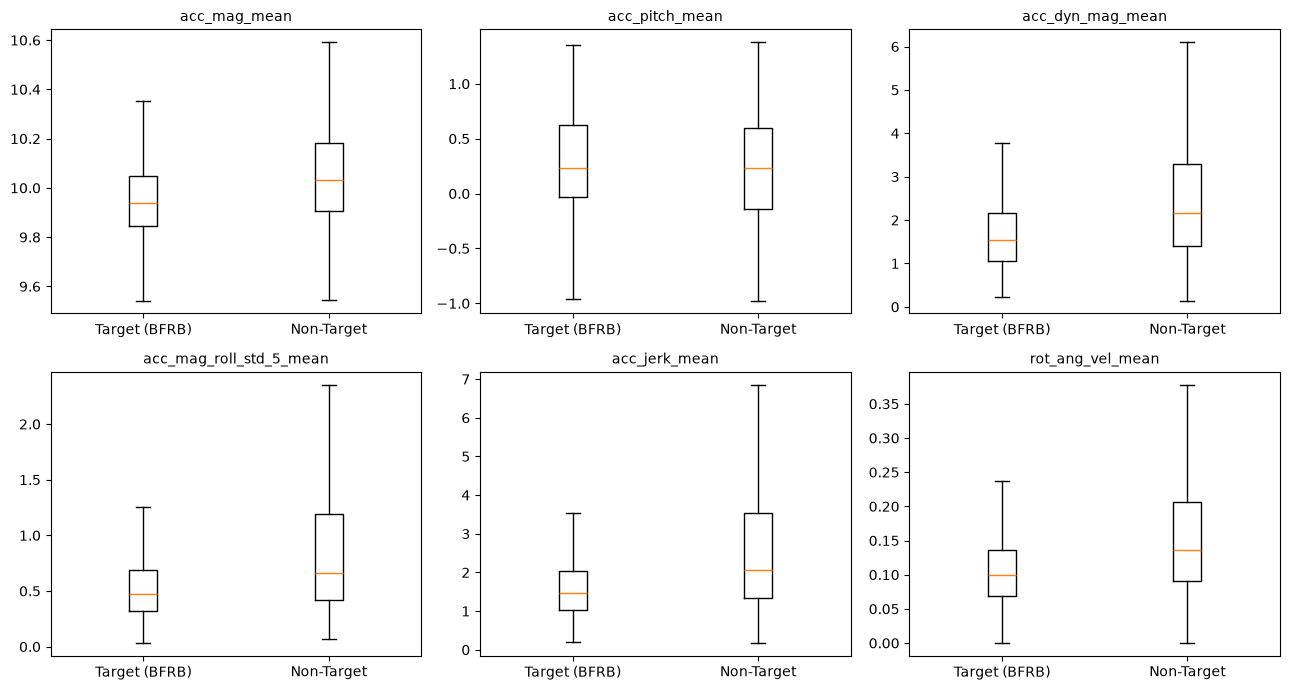

In [17]:
# Attach sequence_type and gesture only for EDA evaluation (never used in preprocessing)
eda_df = imu_proc.merge(
    train[["sequence_id", "sequence_counter", "sequence_type", "gesture"]],
    on=["sequence_id", "sequence_counter"],
    how="left",
)

# Aggregate per sequence to evaluate feature separability
seq_feats = eda_df.groupby(["sequence_id", "sequence_type", "gesture"])[FEATURE_COLS].agg(["mean", "std"])
seq_feats.columns = [f"{c}_{s}" for c, s in seq_feats.columns]
seq_feats = seq_feats.reset_index()

check_cols = [
    "acc_mag_mean",
    "acc_pitch_mean",
    "acc_dyn_mag_mean",
    "acc_mag_roll_std_5_mean",
    "acc_jerk_mean",
    "rot_ang_vel_mean",
]

print("Sequence-level feature median by sequence_type (Target=BFRB vs Non-Target):")
print(seq_feats.groupby("sequence_type")[check_cols].median().round(3).T)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), check_cols):
    target_vals = seq_feats.loc[seq_feats["sequence_type"] == "Target", col]
    non_target_vals = seq_feats.loc[seq_feats["sequence_type"] == "Non-Target", col]
    ax.boxplot([target_vals, non_target_vals], showfliers=False)
    ax.set_xticklabels(["Target (BFRB)", "Non-Target"])
    ax.set_title(col, fontsize=10)

plt.tight_layout()
plt.savefig(FIG_DIR / "imu_feature_separability.png", dpi=150)
plt.show()

In [18]:
# Compare gesture-level medians across engineered IMU features
gesture_summary = (
    seq_feats.groupby("gesture")[
        ["acc_pitch_mean", "acc_roll_mean", "acc_dyn_mag_mean", "acc_mag_roll_std_5_mean", "rot_ang_vel_mean"]
    ]
    .median()
    .sort_values("acc_pitch_mean")
)
print("Gesture-level feature medians (sorted by acc_pitch_mean):")
gesture_summary.round(3)

Gesture-level feature medians (sorted by acc_pitch_mean):


,acc_pitch_mean,acc_roll_mean,acc_dyn_mag_mean,acc_mag_roll_std_5_mean,rot_ang_vel_mean
gesture,,,,,
Write name on leg,-0.373,-1.976,1.578,0.534,0.095
Pinch knee/leg skin,-0.364,-1.937,1.516,0.564,0.104
Scratch knee/leg skin,-0.333,-1.900,1.527,0.531,0.090
Feel around in tray and pull out an object,-0.011,-2.015,1.516,0.457,0.103
Text on phone,0.038,-1.150,1.309,0.378,0.087
Neck - scratch,0.106,0.336,1.537,0.479,0.097
Neck - pinch skin,0.185,0.762,1.644,0.455,0.110
Eyebrow - pull hair,0.210,-0.744,1.436,0.443,0.088
Above ear - pull hair,0.241,0.929,1.836,0.538,0.123


## Tóm tắt phát hiện và quyết định tiền xử lý

Mọi bước xử lý được cài đặt trong hàm `preprocess_imu` tại `src/preprocess_imu.py`, chạy độc lập trên từng `sequence_id`, giữ nguyên số dòng/thứ tự dòng và tương thích hoàn toàn với tập test.

### 1. Xử lý dữ liệu thiếu cho IMU (`rot_missing`, điền Quaternion đơn vị & chuẩn hóa)
- **Làm gì?**
  - Tạo cột cờ nhị phân `rot_missing` (`1` nếu thiếu `rot_*`, `0` nếu đủ).
  - Dùng `ffill`/`bfill` trong từng chuỗi riêng lẻ cho `acc_*` và các phần thiếu lẻ tẻ của `rot_*` (đảm bảo an toàn nếu tập test có dòng thiếu đơn lẻ).
  - Với các chuỗi mất hoàn toàn `rot_*`, điền quaternion đơn vị `(rot_w=1.0, rot_x=0.0, rot_y=0.0, rot_z=0.0)` và chuẩn hóa mọi quaternion về vector đơn vị ($\|q\| = 1$).
- **Vì sao?**
  - Theo `01_eda_overview.ipynb`, `acc_*` không thiếu dòng nào, còn `rot_*` mất trọn vẹn cả chuỗi ở 50 chuỗi (3 người).
  - Điền quaternion đơn vị giữ cho các phép biến đổi góc quay không sinh `NaN`, còn cột `rot_missing` giúp mô hình cây (Tree-based) phân biệt rõ đâu là chuỗi thiếu cảm biến định hướng thực sự.
- **Kiểm chứng thế nào?**
  - Kiểm tra `imu_proc.isna().sum().sum() == 0` sau xử lý và đối chiếu số chuỗi có `rot_missing == 1` khớp với số chuỗi mất `rot_*` ban đầu (50 chuỗi trong train).

### 2. Chuẩn hóa tay thuận (`handedness` mirroring)
- **Làm gì?**
  - Ghép `handedness` từ bảng nhân khẩu học `demo` theo `subject`. Với người thuận tay trái (`handedness == 0`), phản chiếu qua mặt phẳng YZ ($x \mapsto -x$): đảo dấu `acc_x -> -acc_x` và đảo dấu quaternion tương ứng `(rot_w, rot_x, -rot_y, -rot_z)` ở các dòng không thiếu `rot_*`.
- **Vì sao?**
  - Chỉ có 10/81 người (12,3%) thuận tay trái. Do đeo đồng hồ đối xứng giữa tay trái và tay phải, trục `acc_x` của người thuận tay trái bị ngược dấu (đã quan sát trực tiếp ở `SUBJ_002923` trong `01_eda_overview.ipynb`). Nếu không lật dấu, mô hình cây phải tốn thêm nhánh để học riêng cho nhóm thiểu số tay trái.
- **Kiểm chứng thế nào?**
  - So sánh biểu đồ histogram (`imu_handedness_mirroring.png`, `imu_rot_mirroring.png`) và bảng trung bình/trung vị giữa nhóm tay trái và tay phải trước và sau khi mirroring.

### 3. Bổ sung đặc trưng hình học & động lực thời gian cho mô hình cây
- **Làm gì?**
  - *Đặc trưng gia tốc:* `acc_mag` (độ lớn tổng vector), `acc_pitch` & `acc_roll` (góc nghiêng cổ tay từ trọng lực), `acc_jerk` (độ giật giữa 2 bước liên tiếp), `acc_mag_roll_mean_5` & `acc_mag_roll_std_5` (trung bình & độ lệch chuẩn cửa sổ trượt 5 bước), `acc_dyn_mag` (gia tốc động sau khi trừ trung bình trượt 11 bước).
  - *Đặc trưng góc quay:* `rot_roll`, `rot_pitch`, `rot_yaw` (chuyển quaternion sang góc Euler) và `rot_ang_vel` (tốc độ góc giữa 2 bước liên tiếp qua $2 \arccos(|q_t \cdot q_{t-1}|)$).
- **Vì sao?**
  - Nhóm định hướng sử dụng **mô hình cây (Tree-based)** vốn chia ngưỡng độc lập từng cột và không có bộ nhớ thời gian.
  - `acc_pitch`, `acc_roll` và góc Euler giúp cây tách trực tiếp tư thế cổ tay (phân biệt gãi cổ với gãi chân khi dạng dao động giống nhau).
  - `acc_mag_roll_std_5`, `acc_dyn_mag`, `acc_jerk`, `rot_ang_vel` đo trực tiếp mức rung lắc/dao động lặp lại trong pha cử chỉ mà không phụ thuộc độ dài toàn chuỗi. Dùng $|q_t \cdot q_{t-1}|$ loại bỏ nhảy góc giả do tính tương đương dấu $q \equiv -q$.
- **Kiểm chứng thế nào?**
  - Vẽ đồ thị tín hiệu theo thời gian (`imu_engineered_signals.png`) cho thấy `acc_pitch` tách biệt hai tư thế và `acc_dyn_mag` / `acc_mag_roll_std_5` tăng mạnh ở pha `Gesture`.
  - So sánh boxplot phân bố theo `sequence_type` (`imu_feature_separability.png`) và bảng trung vị theo từng cử chỉ (`gesture_summary`).
  - Xác nhận toàn bộ ràng buộc bắt buộc qua `assert` (giữ nguyên số dòng, tương thích tập test, không rò rỉ giữa các chuỗi) và kiểm tra cuối cùng bằng `python src/preprocess.py`.